# Lab 2.2 - Train the Sample Problem with TensorFlow/Keras (IMU-based gesture recognition)

This notebook has `# TODO` markers (TODO 1-5, with TODO 4 split into 4a-4e).
Work through them in order - later cells depend on earlier ones (e.g. the
hyperparameter sweep in Step 2 reuses the `build_model()` function you
complete in `src/cnn2d_model.py` for TODO 2).

The Magic Wand dataset shared in this repo (`dataset/negative`,
`dataset/ring`, `dataset/slope`, `dataset/wing`) is small. To train a model
that generalizes well, you need more data. Before starting this notebook:

1. Build the `data_collection` firmware and flash it onto the Pico (see
   `data_collection/README.md`).
2. Record several sessions per gesture class (negative/ring/slope/wing),
   holding the Pico with the IMU oriented as described in the top-level
   `README.md` (x right, y back, z up).
3. Copy the recorded `.txt` files off the SD card, together with copies of
   the matching files from the shared `dataset/<class_name>/` folders, into
   `dataset/custom/<class_name>/` - so each of the four class folders under
   `dataset/custom/` ends up containing both the shared recordings and your
   own.

Once `dataset/custom/` is populated with all four classes, you're ready for
Step 0 below.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# Make the helper modules in src/ importable (preprocessor.py, cnn2d_model.py)
SRC_DIR = str(Path.cwd() / "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

tf.random.set_seed(10)
np.random.seed(10)

print("TensorFlow version:", tf.__version__)

I0000 00:00:1794948304.537239      64 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794948305.474051      64 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794948308.339790      64 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## Step 0 - Prepare the dataset

Unlike MNIST, there's no `tf.keras.datasets` loader for this problem - you
collected the raw recordings yourself, so you first need to turn them into
a fixed-length numpy array the model can train on. `src/preprocessor.py`
already implements the full pipeline (load CSV, convert to g, filter,
resample to a fixed length, split, normalize); you just need to call it.

**TODO 1:** Call `prepare_dataset(target_length=128)` to preprocess every
`.txt` recording under `dataset/custom/<class_name>/` and cache the result
as a `.npz` file at `DEFAULT_OUTPUT_PATH` (pass `target_length=128` so the
saved sequences match the `(128, 3, 1)` input shape `build_model()` expects
in Step 1). Then call `load_prepared_dataset(DEFAULT_OUTPUT_PATH)` to load
it back as a dict of `(X, y)` pairs per split. You only need to call
`prepare_dataset(...)` again if you add more recordings later.

In [2]:
from pathlib import Path
import numpy as np
from src.preprocessor import (
    discover_recordings, load_csv, split_recordings, preprocess_split,
    fit_normalizer, normalize, DEFAULT_OUTPUT_PATH, COUNTS_PER_G
)

CLASS_NAMES = ("negative", "ring", "slope", "wing", "n_shape")
DATASET_DIR = Path.cwd() / "dataset" / "custom"
ROW_COUNT_THRESHOLD = 5000  # GitHub originals sampling sets land well below this, my own recordings are longer
TARGET_LENGTH = 128
CUTOFF_HZ = 20.0

# TODO 1a: call discover_recordings(DATASET_DIR, CLASS_NAMES) to get every (path, label) pair
records, class_names = discover_recordings(DATASET_DIR, CLASS_NAMES)

# TODO 1b: partition `records` into two lists by row count.
# For each (path, label) in records, load it and check len(...) against
records_github = []
records_own = []
for path, label in records:
        SamplesAsCSV = load_csv(path)
        if(len(SamplesAsCSV)<ROW_COUNT_THRESHOLD):
            records_github.append((path,label))
        else:
            records_own.append((path,label))
            
# TODO 1c: split each calibration group independently
splits_github = split_recordings(records_github)
splits_own = split_recordings(records_own)
            

print(f"github-calibration files: {len(records_github)}") # Just to recheck that I sorted the preprocessed dataset correctly
print(f"own-calibration files: {len(records_own)}")

SAMPLE_RATE_HZ = 2156

merged = {}
for split_name in ("train", "validation", "test"):
    
    # TODO: call preprocess_split() on splits_github[split_name],
    # with expected_duration_seconds=2.0
    gestures_gh, labels_gh, files_gh = preprocess_split(splits_github[split_name], sample_rate_hz = 2156, target_length = 128, expected_duration_seconds = 2.0)

    
    # TODO: call preprocess_split() on splits_own[split_name],
    # with expected_duration_seconds=3.0
    gestures_own, labels_own, files_own = preprocess_split(splits_own[split_name], sample_rate_hz = 2156, target_length = 128, expected_duration_seconds = 3.0)

    # TODO: concatenate each pair (gestures, labels, filenames) together
    g = np.concatenate([gestures_gh, gestures_own])
    l = np.concatenate([labels_gh, labels_own])
    f = np.concatenate([files_gh, files_own])
    merged[split_name] = (g, l, f)

for name, (g, l, f) in merged.items():
    print(name, g.shape, l.shape, f.shape) 

train_gestures, train_labels, train_files = merged["train"]
statistics = fit_normalizer(train_gestures)

saved = {
    "class_names": np.asarray(class_names),
    "mean": statistics["mean"],
    "std": statistics["std"],
    "sample_rate_hz": np.asarray(SAMPLE_RATE_HZ),
    "counts_per_g": np.asarray(COUNTS_PER_G),
    "target_length": np.asarray(TARGET_LENGTH),
    "cutoff_hz": np.asarray(CUTOFF_HZ),
}

for name, (gestures, labels, files) in merged.items():
    saved[f"X_{name}"] = normalize(gestures, statistics) # call normalize(gestures, statistics) here
    saved[f"y_{name}"] = labels
    saved[f"files_{name}"] = files

# TODO: call np.savez_compressed(DEFAULT_OUTPUT_PATH, **saved)
np.savez_compressed(DEFAULT_OUTPUT_PATH, **saved)



negative: 50 recordings
ring: 50 recordings
slope: 50 recordings
wing: 50 recordings
n_shape: 50 recordings
github-calibration files: 100
own-calibration files: 150
train (150, 128, 3) (150,) (150,)
validation (50, 128, 3) (50,) (50,)
test (50, 128, 3) (50,) (50,)


In [3]:
from src.preprocessor import DEFAULT_OUTPUT_PATH, load_prepared_dataset
import numpy as np

# TODO 1: call prepare_dataset(...) once to preprocess and cache the dataset,
# then load it back with load_prepared_dataset(...)
dataset = load_prepared_dataset(DEFAULT_OUTPUT_PATH) #The dataset was prepared in the last cell.

X_train, y_train = dataset["train"]
X_validation, y_validation = dataset["validation"]
X_test, y_test = dataset["test"]

# Conv2D expects a trailing channel dimension: (time, 3) -> (time, 3, 1)
X_train = X_train[..., np.newaxis]
X_validation = X_validation[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("X_train:", X_train.shape, " X_validation:", X_validation.shape,
      " X_test:", X_test.shape)
print("Classes:", dataset["class_names"])

X_train: (150, 128, 3, 1)  X_validation: (50, 128, 3, 1)  X_test: (50, 128, 3, 1)
Classes: ['negative', 'ring', 'slope', 'wing', 'n_shape']


## Step 1 - Build and train a small CNN

Architecture (complete this in `src/cnn2d_model.py`, not in the notebook -
you'll import `build_model()` both here and again in Step 2):

`Input (time, 3, 1) -> Conv2D(num_filters1, kernel=(4,3), padding="same", activation) -> MaxPool2D((3,3), strides=(3,3), padding="same") -> Conv2D(num_filters2, kernel=(4,1), padding="same", activation) -> MaxPool2D((3,1), strides=(3,1), padding="same") -> Flatten -> Dropout(dropout) -> Dense(dense_units, activation) -> Dropout(dropout) -> Dense(num_classes, softmax)`

Default hyperparameters: `num_filters1=8, num_filters2=16, dense_units=16,
activation="relu", dropout=0.1` - these give the baseline model; you'll vary
them in Step 2's sweep.

A couple of things worth knowing before you write this:
- The first conv/pool block convolves across both time and the 3
  acceleration axes; by the time the second conv runs, the axis dimension
  has already been pooled down to 1, so the second conv only convolves
  along time (hence the `(4, 1)` kernel instead of `(4, 3)`).
- Every op used here (`Conv2D`, `MaxPooling2D`, `Flatten`, `Dropout`,
  `Dense`) maps onto a kernel included in TFLite Micro's standard op
  resolver - this matters once the model gets deployed to the Pico.
- `input_shape` and `num_classes` are *not* hyperparameters to sweep - pass
  them in from the data (`X_train.shape[1:]` and
  `len(dataset["class_names"])`), don't hardcode numbers.

**TODO 2:** Open `src/cnn2d_model.py` and complete `build_model()` following
the architecture above.

In [4]:
from cnn2d_model import build_model
input_shape=X_train.shape[1:]
num_classes=len(dataset["class_names"])

model = build_model(
    input_shape=input_shape,
    num_classes=num_classes,
)
model.summary()

E0000 00:00:1794948313.983524      64 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 3, 8)      │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 43, 1, 8)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 43, 1, 16)      │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 1, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         3,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,573 (17.86 KB)

 Trainable params: 4,573 (17.86 KB)

 Non-trainable params: 0 (0.00 B)

**TODO 3:** Compile and train the model.
- Optimizer: `"adam"`
- Loss: sparse categorical crossentropy (labels are integer class indices,
  not one-hot)
- Metric: accuracy
- Train for enough epochs to see the validation curve flatten out (try ~30
  as a starting point), batch size 16, using `(X_validation, y_validation)`
  as validation data.

In [5]:
# TODO 3: compile and fit the model, capturing the returned History object
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=30, batch_size=16, validation_data=(X_validation, y_validation))

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.1600 - loss: 1.6574 - val_accuracy: 0.2400 - val_loss: 1.5866
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3667 - loss: 1.5516 - val_accuracy: 0.3200 - val_loss: 1.5220
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4400 - loss: 1.4754 - val_accuracy: 0.4200 - val_loss: 1.4603
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4067 - loss: 1.4316 - val_accuracy: 0.5000 - val_loss: 1.3853
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5133 - loss: 1.3396 - val_accuracy: 0.5200 - val_loss: 1.2906
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5400 - loss: 1.2378 - val_accuracy: 0.5600 - val_loss: 1.1853
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5200 - loss: 1.1327 - val_accuracy: 0.6200 - val_loss: 1.0874
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5467 - loss: 1.0433 - val_accuracy: 0.6400 - v

Baseline model -- test accuracy: 0.8600, test loss: 0.4900


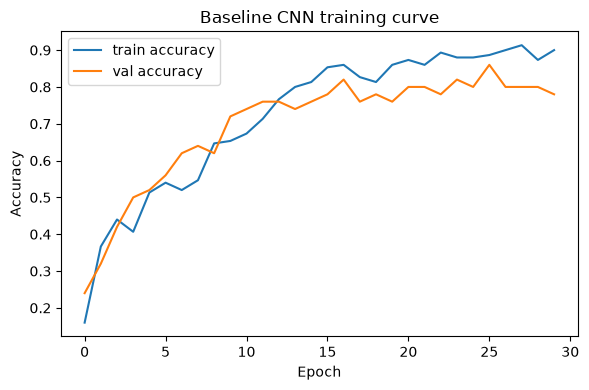

In [6]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Baseline model -- test accuracy: {test_acc:.4f}, test loss: {test_loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN training curve")
plt.legend()
plt.tight_layout()
plt.savefig("baseline_training_curve.png", dpi=110)
plt.show()

## Step 2 - Experiment with training parameters

Try changing each of the following, one at a time, and note the effect on
accuracy, training time, and model size:

- Learning rate
- Optimizer (SGD vs Adam vs RMSprop)
- Number of epochs
- Batch size
- Activation functions
- Number of filters/neurons per layer (`num_filters1`, `num_filters2`,
  `dense_units`)
- Dropout

**TODO 4:** Complete `run_experiment()` below (build, train, and evaluate a
model, timing the training run and counting its trainable parameters), then
add your own entries to the `results` list - at least one experiment per
bullet point above. Reuse `build_model()` and `run_experiment()`; don't
rewrite the training loop by hand for each one.

In [7]:
# SGD learning rates, default is 0.01.
sgd_custom_rate1 = tf.keras.optimizers.SGD(learning_rate=0.0001)
sgd_custom_rate2 = tf.keras.optimizers.SGD(learning_rate=0.001)
sgd_custom_rate3 = tf.keras.optimizers.SGD(learning_rate=0.1)

# RMSprop learning rates, 0.001 is the default one.
rms_custom_rate1 = tf.keras.optimizers.RMSprop(learning_rate=0.0001)
rms_custom_rate2 = tf.keras.optimizers.RMSprop(learning_rate=0.01)
rms_custom_rate3 = tf.keras.optimizers.RMSprop(learning_rate=0.1)

# Adam learning rates, 0.001 is the default one.
adam_custom_rate1 = tf.keras.optimizers.Adam(learning_rate=0.0001)
adam_custom_rate2 = tf.keras.optimizers.Adam(learning_rate=0.01)
adam_custom_rate3 = tf.keras.optimizers.Adam(learning_rate=0.1)


def count_params(m):
    return int(np.sum([tf.keras.backend.count_params(w) for w in m.trainable_weights]))

def run_experiment(name, optimizer, epochs=24, batch_size=20, activation="leaky_relu",
                    num_filters1=8, num_filters2=16, dense_units=16, dropout=0.1, l2_lambda=0.0):
    tf.random.set_seed(10)  # To guarantee fairness and even odds for the training runs.
    # TODO 4a: build the model with the given hyperparameters
    m = build_model(input_shape, num_classes, num_filters1=num_filters1, num_filters2=num_filters2,
                 dense_units=dense_units, activation=activation, dropout=dropout, l2_lambda=l2_lambda)

    # TODO 4b: compile it (same loss/metric as Step 1) with the given optimizer
    m.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    start = time.time()
    # TODO 4c: time a call to m.fit() with the given epochs/batch_size
    # (verbose=0), using (X_validation, y_validation) as validation data
    m.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_validation, y_validation), verbose=0)
    elapsed = time.time() - start

    # TODO 4d: evaluate on the test set and count trainable params
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    n_params = count_params(m)

    return {
        "experiment": name,
        "test_accuracy": round(acc, 4),
        "train_time_sec": round(elapsed, 1),
        "trainable_params": n_params,
    }

# TODO 4e: add at least one run_experiment(...) call per bullet point above
results = []


results.append(run_experiment("changed to (sgd, lr=0.1, epochs = 24", optimizer=sgd_custom_rate3))

results.append(run_experiment("changed to (RMSprop, lr=default, epochs = 24", optimizer="rmsprop"))

results.append(run_experiment("baseline (adam, lr=default), epochs = 24", optimizer="adam"))
results.append(run_experiment("baseline (adam, lr=0.01), epochs = 24", optimizer=adam_custom_rate2))

results_df = pd.DataFrame(results)
results_df

,experiment,test_accuracy,train_time_sec,trainable_params
0,"changed to (sgd, lr=0.1, epochs = 24",0.86,4.3,4573
1,"changed to (RMSprop, lr=default, epochs = 24",0.84,4.7,4573
2,"baseline (adam, lr=default), epochs = 24",0.84,5.3,4573
3,"baseline (adam, lr=0.01), epochs = 24",0.90,5.3,4573


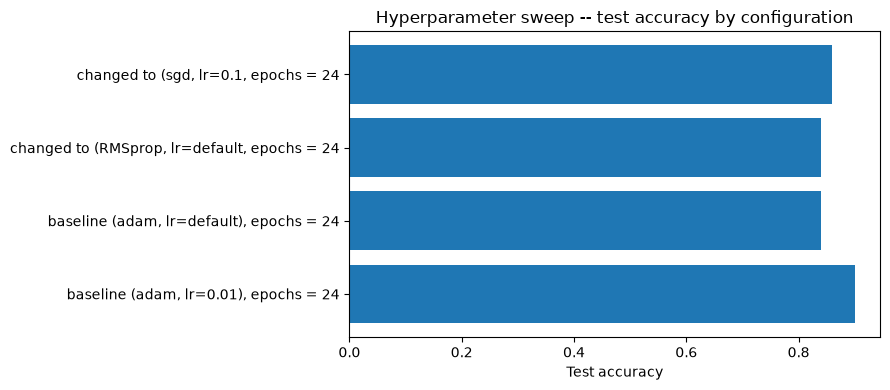

Best configuration in this sweep:
experiment          baseline (adam, lr=0.01), epochs = 24
test_accuracy                                         0.9
train_time_sec                                        5.3
trainable_params                                     4573
Name: 3, dtype: object


In [8]:
plt.figure(figsize=(9, 4))
plt.barh(results_df["experiment"], results_df["test_accuracy"])
plt.xlabel("Test accuracy")
plt.title("Hyperparameter sweep -- test accuracy by configuration")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("hyperparameter_sweep.png", dpi=110)
plt.show()

best_row = results_df.loc[results_df["test_accuracy"].idxmax()]
print("Best configuration in this sweep:")
print(best_row)

## Step 3 - Save the trained model

**TODO 5:** Save the model in both `.h5` and `SavedModel` format.
- `model.save("magic_wand_cnn.h5")` saves the legacy HDF5 format.
- `model.export("magic_wand_cnn_savedmodel")` exports a `SavedModel` (Keras
  3's `model.save()` no longer writes `SavedModel` for an extension-less
  path the way `tf_keras.Model.save()` does in the MNIST notebook - use
  `.export(...)` here instead).

Keep both files/folders safe if you continue on to quantization or
on-device deployment.

In [10]:
# TODO 5: save the model as magic_wand_cnn.h5 and as a SavedModel export
final_model = build_model(input_shape, num_classes, num_filters1=8, num_filters2=16, dense_units=16, activation="leaky_relu", dropout=0.1, l2_lambda=0.0)
final_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01) ,loss="sparse_categorical_crossentropy", metrics=["accuracy"])
final_model.fit(X_train, y_train, epochs=24 , batch_size=20 , validation_data=(X_validation, y_validation))
final_model.save("magic_wand_cnn.h5")
final_model.save("magic_wand_cnn.keras")
final_model.export("magic_wand_cnn_saved_model")

Epoch 1/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.3533 - loss: 1.4456 - val_accuracy: 0.4400 - val_loss: 1.0878
Epoch 2/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5933 - loss: 0.9637 - val_accuracy: 0.8000 - val_loss: 0.7438
Epoch 3/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7133 - loss: 0.7390 - val_accuracy: 0.7200 - val_loss: 0.7080
Epoch 4/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8000 - loss: 0.6094 - val_accuracy: 0.7400 - val_loss: 0.8372
Epoch 5/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8267 - loss: 0.5669 - val_accuracy: 0.8400 - val_loss: 0.5457
Epoch 6/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9267 - loss: 0.3534 - val_accuracy: 0.8400 - val_loss: 0.7616
Epoch 7/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8667 - loss: 0.3580 - val_accuracy: 0.8000 - val_loss: 0.7214
Epoch 8/24
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9267 - loss: 0.2137 - val_accuracy: 0.8200 - val_loss: 0.6866


INFO:tensorflow:Assets written to: magic_wand_cnn_saved_model/assets


INFO:tensorflow:Assets written to: magic_wand_cnn_saved_model/assets


Saved artifact at 'magic_wand_cnn_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='keras_tensor_50')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  129610769846096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769846480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769858192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769842832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769849936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769849744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769847248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129610769847632: TensorSpec(shape=(), dtype=tf.resource, name=None)


## Discussion Topics

Answer in a few sentences each:

1. Which single hyperparameter gave you the biggest accuracy gain (or loss)?
2. How much did adding your own collected recordings (vs. only the small
   shared dataset) change validation/test accuracy? What does that tell you
   about generalization?
3. What's the tradeoff between model size and accuracy in your experiments?